# Firewall Traffic Log Analysis

**Goal:** profile allowed vs. blocked connections in a public firewall dataset, find which ports and services attract the most blocked traffic, and flag unusual sessions.

**Dataset:** Internet Firewall Data (UCI Machine Learning Repository / Kaggle), saved as `data/log2.csv`. Each row is one logged session.

**Tools:** Python, pandas, matplotlib, seaborn

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
Path("figures").mkdir(exist_ok=True)

df = pd.read_csv("data/log2.csv")
df.shape

(65532, 12)

## 1. Data quality checks

In [2]:
df.columns = (df.columns.str.strip().str.lower()
              .str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_"))
print(df.dtypes)
print("\nMissing values:\n", df.isna().sum())
print("\nDuplicate rows:", df.duplicated().sum())
df.describe().T

source_port             int64
destination_port        int64
nat_source_port         int64
nat_destination_port    int64
action                    str
bytes                   int64
bytes_sent              int64
bytes_received          int64
packets                 int64
elapsed_time_sec        int64
pkts_sent               int64
pkts_received           int64
dtype: object

Missing values:
 source_port             0
destination_port        0
nat_source_port         0
nat_destination_port    0
action                  0
bytes                   0
bytes_sent              0
bytes_received          0
packets                 0
elapsed_time_sec        0
pkts_sent               0
pkts_received           0
dtype: int64

Duplicate rows: 8362


,count,mean,std,min,25%,50%,75%,max
source_port,65532.0,49391.969343,1.525571e+04,0.0,49183.0,53776.5,58638.00,6.553400e+04
destination_port,65532.0,10577.385812,1.846603e+04,0.0,80.0,445.0,15000.00,6.553500e+04
nat_source_port,65532.0,19282.972761,2.197069e+04,0.0,0.0,8820.5,38366.25,6.553500e+04
nat_destination_port,65532.0,2671.049930,9.739162e+03,0.0,0.0,53.0,443.00,6.553500e+04
bytes,65532.0,97123.950085,5.618439e+06,60.0,66.0,168.0,752.25,1.269359e+09
bytes_sent,65532.0,22385.796908,3.828139e+06,60.0,66.0,90.0,210.00,9.484772e+08
bytes_received,65532.0,74738.153177,2.463208e+06,0.0,0.0,79.0,449.00,3.208818e+08
packets,65532.0,102.866035,5.133002e+03,1.0,1.0,2.0,6.00,1.036116e+06
elapsed_time_sec,65532.0,65.833577,3.024618e+02,0.0,0.0,15.0,30.00,1.082400e+04
pkts_sent,65532.0,41.399530,3.218871e+03,1.0,1.0,1.0,3.00,7.475200e+05


Exact duplicate rows can be legitimate repeated sessions in a firewall log, so they are **kept** here, not dropped. Note the decision in the findings below.

## 2. Allowed vs. blocked traffic

,sessions,percent
action,,
allow,37640,57.44
deny,14987,22.87
drop,12851,19.61
reset-both,54,0.08


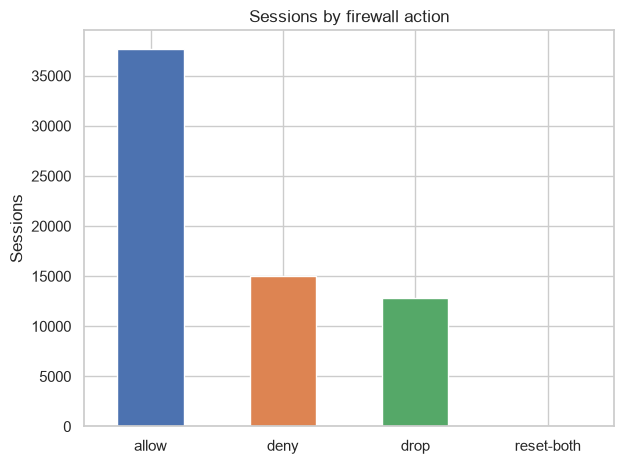

In [3]:
action_counts = df["action"].value_counts()
action_pct = (action_counts / len(df) * 100).round(2)
summary = pd.DataFrame({"sessions": action_counts, "percent": action_pct})
display(summary)

ax = action_counts.plot(kind="bar", color=sns.color_palette("deep"))
ax.set_title("Sessions by firewall action")
ax.set_ylabel("Sessions")
ax.set_xlabel("")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("figures/01_action_counts.png", dpi=150)
plt.show()

## 3. Which destination ports see the most traffic, and the most blocking?

In [10]:
# Well-known services for common ports (extend as needed)
SERVICES = {21: "FTP", 22: "SSH", 23: "Telnet", 25: "SMTP", 53: "DNS", 80: "HTTP",
            110: "POP3", 123: "NTP", 135: "MS-RPC", 137: "NetBIOS", 139: "NetBIOS",
            143: "IMAP", 161: "SNMP", 389: "LDAP", 443: "HTTPS", 445: "SMB",
            993: "IMAPS", 1433: "MSSQL", 3306: "MySQL", 3389: "RDP", 5432: "PostgreSQL",
            8080: "HTTP-alt", 5900: "VNC"}

df["blocked"] = (df["action"] != "allow").astype(int)

port = (df.groupby("destination_port")
          .agg(sessions=("action", "size"), blocked=("blocked", "sum"))
          .assign(block_rate=lambda x: (x["blocked"] / x["sessions"] * 100).round(1),
                  service=lambda x: x.index.map(SERVICES).fillna("other"))
          .sort_values("sessions", ascending=False))

top_ports = port.head(15)
display(top_ports)

,sessions,blocked,block_rate,service
destination_port,,,,
53,15414,29,0.2,DNS
445,12891,12891,100.0,SMB
443,11684,7,0.1,HTTPS
80,4035,7,0.2,HTTP
25174,1087,1087,100.0,other
5900,909,854,93.9,VNC
37965,826,826,100.0,other
22114,767,767,100.0,other
64147,756,756,100.0,other


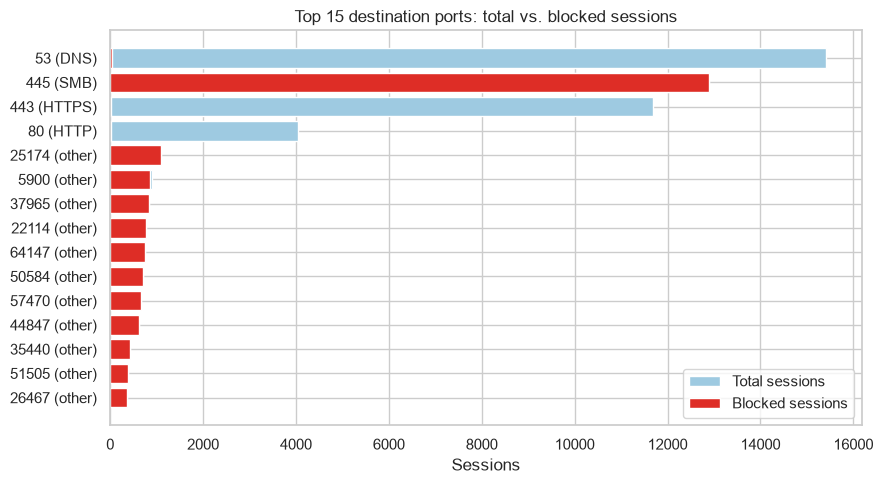

In [5]:
fig, ax = plt.subplots(figsize=(9, 5))
labels = [f"{p} ({s})" for p, s in zip(top_ports.index, top_ports["service"])]
ax.barh(labels[::-1], top_ports["sessions"][::-1], label="Total sessions", color="#9ecae1")
ax.barh(labels[::-1], top_ports["blocked"][::-1], label="Blocked sessions", color="#de2d26")
ax.set_title("Top 15 destination ports: total vs. blocked sessions")
ax.set_xlabel("Sessions")
ax.legend()
plt.tight_layout()
plt.savefig("figures/02_top_ports.png", dpi=150)
plt.show()

### Ports with a high block rate (minimum 50 sessions so small samples don't distort the rate)

In [11]:
risky = (port[(port["sessions"] >= 50) & (port.index < 1024)]
         .sort_values("block_rate", ascending=False)
         .head(15))
display(risky[["service", "sessions", "blocked", "block_rate"]])

,service,sessions,blocked,block_rate
destination_port,,,,
445,SMB,12891,12891,100.0
23,Telnet,363,346,95.3
1,other,85,66,77.6
22,SSH,119,81,68.1
0,other,173,88,50.9
123,NTP,169,13,7.7
53,DNS,15414,29,0.2
80,HTTP,4035,7,0.2
443,HTTPS,11684,7,0.1


## 4. Traffic volume by action

bytes                    packets                  \
                mean median         max    mean median      max   
action                                                            
allow       169038.0  422.0  1269359015   178.3    3.0  1036116   
deny            83.2   66.0        1850     1.0    1.0        5   
drop            68.7   70.0          70     1.0    1.0        1   
reset-both     157.4  145.0         293     1.7    1.0        4   

           elapsed_time_sec                
                       mean median    max  
action                                     
allow                 114.6   30.0  10824  
deny                    0.0    0.0      1  
drop                    0.0    0.0      0  
reset-both              0.1    0.0      1

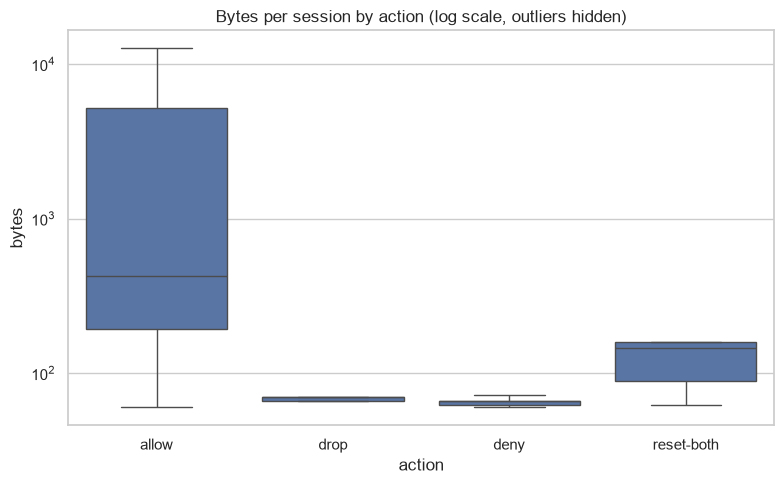

In [7]:
vol = df.groupby("action")[["bytes", "packets", "elapsed_time_sec"]].agg(["mean", "median", "max"]).round(1)
display(vol)

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(data=df, x="action", y="bytes", showfliers=False, ax=ax)
ax.set_yscale("log")
ax.set_title("Bytes per session by action (log scale, outliers hidden)")
plt.tight_layout()
plt.savefig("figures/03_bytes_by_action.png", dpi=150)
plt.show()

## 5. Outlier sessions

In [8]:
# Flag sessions with unusually large byte counts using the IQR rule, per action
def iqr_flags(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return s > q3 + 3 * (q3 - q1)

df["large_session"] = df.groupby("action")["bytes"].transform(iqr_flags)
print("Flagged sessions:", int(df["large_session"].sum()),
      f"({df['large_session'].mean()*100:.2f}% of all sessions)")

outliers = (df[df["large_session"]]
            .sort_values("bytes", ascending=False)
            .head(10)[["destination_port", "action", "bytes", "packets", "elapsed_time_sec"]])
display(outliers)

Flagged sessions: 5709 (8.71% of all sessions)


,destination_port,action,bytes,packets,elapsed_time_sec
10220,15187,allow,1269359015,1036116,9283
61429,3478,allow,428935914,635946,2242
63595,443,allow,307104860,234597,6122
40689,443,allow,242735602,238334,3604
33967,62336,allow,127653507,161030,2162
47827,443,allow,126490514,123275,553
23851,443,allow,122293139,125460,331
48412,443,allow,119425284,93687,498
58370,80,allow,78198970,79332,368
57556,3389,allow,62242217,123738,4772


In [9]:
# Allowed sessions that sent traffic but received nothing back can indicate one-way or failed flows
one_way = df[(df["action"] == "allow") & (df["bytes_received"] == 0) & (df["bytes_sent"] > 0)]
print("Allowed one-way sessions:", len(one_way),
      f"({len(one_way)/ (df['action'] == 'allow').sum() * 100:.2f}% of allowed sessions)")
one_way.groupby("destination_port").size().sort_values(ascending=False).head(10)

Allowed one-way sessions: 3702 (9.84% of allowed sessions)


destination_port
53       444
80       160
443      152
0         46
6881      45
5900      25
8999      23
27015     21
1024      21
8100      21
dtype: int64

## 6. Findings

*Fill this section in using your actual results. Describe what the tables above show, in your own words.*

- **Allowed vs. blocked:** _what share of sessions was blocked, and which block action dominates?_
- **Busiest ports:** _which services carry the most traffic?_
- **Highest block rates:** _which ports are blocked most, and what service is behind them?_
- **Outliers:** _what do the largest sessions look like?_
- **Limitations:** the dataset has no IP addresses or timestamps, so it can't show source-based scanning or time-of-day patterns.

## 7. Recommendations

*Write 2–3 practical suggestions (for example, which ports to review in the rule set) based on your findings above.*